# Análise do Desempenho Olímpico e Características Socioeconômicas

**Grupo:** Erick Souza Alberti, Felipe Augusto da Silva Cruz e Guilherme Henrique Pereira da Cunha

## Introdução

Os Jogos Olímpicos são o maior evento esportivo do mundo e possuem grande relevância esportiva, sociocultural e de projeção internacional para os países participantes. O desempenho de cada país costuma ser resumido pelo número absoluto de medalhas, uma medida que pode dificultar comparações entre nações com populações, economias e estruturas esportivas muito diferentes.

Neste trabalho, investigamos **possíveis relações entre o desempenho olímpico dos países e características socioeconômicas**, especialmente população total, Produto Interno Bruto (PIB) e PIB per capita. A análise se concentra nos **Jogos Olímpicos de Verão**.

Como as fontes possuem coberturas temporais diferentes, serão utilizados dois recortes. Nas perguntas que dependem apenas dos dados olímpicos, serão consideradas todas as edições de Verão disponíveis, de **1896 a 2024**. Já nas perguntas que envolvem indicadores do World Bank, serão consideradas as edições de Verão entre **1960 e 2024**, período em que há sobreposição entre os dados olímpicos e os indicadores socioeconômicos utilizados.

Ao longo do estudo, o desempenho será medido de formas complementares, como número total de medalhas, participação no total de medalhas de cada edição e medidas relativas, como medalhas por milhão de habitantes. As relações encontradas serão interpretadas como **associações**, e não como evidência de causalidade.


**Link do Repositório no GitHub:** https://github.com/felipeascruz/AEDV

## Descrição dos Dados

O trabalho utiliza três fontes: dois arquivos CSV com dados olímpicos e indicadores socioeconômicos obtidos pela API do World Bank.

* **Medal Table:** contém o resultado agregado de cada país em cada edição dos Jogos Olímpicos de Verão e de Inverno, de 1896 a 2026. Cada linha corresponde a um país em uma edição ou subedição, e aparecem apenas países que conquistaram ao menos uma medalha. A base possui 1.929 linhas e 11 colunas. Como as medalhas de esportes coletivos são contabilizadas uma única vez, esta tabela será utilizada como fonte principal para o total oficial de medalhas. Em 1956, a subedição equestre de Estocolmo aparece separadamente da edição de Melbourne; por isso, os registros serão agregados por **ano e NOC** antes das análises.

* **Olympic Athletes:** contém 315.094 registros de participação de atletas, com 16 colunas. Cada linha representa um atleta em um evento, de modo que um mesmo atleta pode aparecer diversas vezes. Esta base será usada principalmente para identificar **todos os países participantes em cada edição**, inclusive aqueles que conquistaram zero medalhas.

* **World Bank (API):** fornece indicadores anuais por país. Serão utilizados população total, PIB em dólares correntes e PIB per capita em dólares correntes. O arquivo coletado possui dados entre 1960 e 2025; como a última edição de Verão disponível é 2024, as análises socioeconômicas utilizarão as edições entre **1960 e 2024**.

### Combinação das bases

A unidade principal de análise será **país × edição olímpica**. Primeiro, a lista de participantes será obtida da base de atletas. Em seguida, o quadro de medalhas será agregado por `year` e `noc` e combinado à lista de participantes com uma junção à esquerda. Países participantes que não aparecem no quadro de medalhas receberão valor zero para ouro, prata, bronze e total, evitando que países sem medalhas sejam excluídos das análises.

Os códigos do World Bank seguem majoritariamente o padrão ISO, enquanto os dados olímpicos utilizam códigos NOC. Será feita uma padronização explícita dos identificadores antes da junção por `year + noc`. Casos históricos ou delegações sem correspondência socioeconômica defensável serão mantidos como dados ausentes, em vez de receberem uma correspondência arbitrária. Os valores ausentes de população, PIB e PIB per capita também **não serão removidos globalmente**: cada pergunta utilizará apenas as observações que possuírem os indicadores necessários para aquela análise.


In [1]:
# Coleta dos indicadores socioeconômicos do World Bank
from pathlib import Path

# Códigos oficiais das variáveis de interesse:
# SP.POP.TOTL: População total
# NY.GDP.MKTP.CD: PIB (US$ correntes)
# NY.GDP.PCAP.CD: PIB per capita (US$ correntes)
indicadores_wb = {
    'SP.POP.TOTL': 'population',
    'NY.GDP.MKTP.CD': 'gdp',
    'NY.GDP.PCAP.CD': 'gdp_per_capita'
}

# Se o CSV já estiver disponível, reutiliza o arquivo. Isso evita uma chamada
# desnecessária à API e torna a execução reproduzível mesmo sem internet.
if Path('world_bank.csv').exists():
    print('world_bank.csv encontrado: utilizando o arquivo local.')
else:
    import wbgapi as wb

    df_world_bank = wb.data.DataFrame(
        indicadores_wb.keys(),
        time=range(1960, 2026),
        labels=True,
        numericTimeKeys=True
    ).reset_index()

    df_world_bank.to_csv('world_bank.csv', index=False)
    print('world_bank.csv criado a partir da API do World Bank.')


world_bank.csv encontrado: utilizando o arquivo local.


In [2]:
# Importação, limpeza e combinação das bases
import pandas as pd
from IPython.display import display

df_medalhas = pd.read_csv('medal_table.csv')
df_atletas = pd.read_csv('olympic_athletes.csv')
df_world_bank = pd.read_csv('world_bank.csv')

# -----------------------------
# 1. Preparação do World Bank
# -----------------------------

# Transforma as colunas de anos em uma única coluna 'year'.
df_world_bank = df_world_bank.melt(
    id_vars=['economy', 'series', 'Country', 'Series'],
    var_name='year',
    value_name='valor'
)

# Pivota a tabela para que população, PIB e PIB per capita tenham colunas próprias.
df_world_bank = df_world_bank.pivot_table(
    index=['economy', 'Country', 'year'],
    columns='series',
    values='valor'
).reset_index()

df_world_bank['year'] = df_world_bank['year'].astype(int)
df_world_bank = df_world_bank.rename(columns=indicadores_wb)
df_world_bank = df_world_bank.rename(columns={'economy': 'iso', 'Country': 'country'})

# O código CHI do World Bank corresponde a Channel Islands e conflita com o NOC CHI do Chile.
# Channel Islands não compete como um NOC próprio, então esse registro é removido antes da conversão.
df_world_bank = df_world_bank[df_world_bank['iso'] != 'CHI'].copy()

# Conversão dos códigos ISO do World Bank para os códigos NOC utilizados na base olímpica.
iso_para_noc = {
    'DZA': 'ALG', 'AGO': 'ANG', 'ATG': 'ANT', 'ABW': 'ARU', 'ASM': 'ASA', 'BHS': 'BAH', 'BGD': 'BAN', 'BRB': 'BAR',
    'BMU': 'BER', 'BTN': 'BHU', 'BLZ': 'BIZ', 'BWA': 'BOT', 'BHR': 'BRN', 'BRN': 'BRU', 'BGR': 'BUL', 'BFA': 'BUR',
    'KHM': 'CAM', 'CYM': 'CAY', 'COG': 'CGO', 'TCD': 'CHA', 'CHL': 'CHI', 'CRI': 'CRC', 'HRV': 'CRO', 'DNK': 'DEN',
    'SLV': 'ESA', 'FJI': 'FIJ', 'GMB': 'GAM', 'GNB': 'GBS', 'GNQ': 'GEQ', 'DEU': 'GER', 'GRC': 'GRE', 'GRD': 'GRN',
    'GTM': 'GUA', 'GIN': 'GUI', 'HTI': 'HAI', 'HND': 'HON', 'IDN': 'INA', 'IRN': 'IRI', 'VIR': 'ISV', 'VGB': 'IVB',
    'XKX': 'KOS', 'SAU': 'KSA', 'KWT': 'KUW', 'LVA': 'LAT', 'LBY': 'LBA', 'LSO': 'LES', 'MDG': 'MAD', 'MYS': 'MAS',
    'MWI': 'MAW', 'MNG': 'MGL', 'MCO': 'MON', 'MUS': 'MRI', 'MRT': 'MTN', 'MMR': 'MYA', 'NIC': 'NCA', 'NLD': 'NED',
    'NPL': 'NEP', 'NGA': 'NGR', 'NER': 'NIG', 'OMN': 'OMA', 'PRY': 'PAR', 'PHL': 'PHI', 'PSE': 'PLE', 'PRT': 'POR',
    'PRI': 'PUR', 'ZAF': 'RSA', 'WSM': 'SAM', 'SYC': 'SEY', 'KNA': 'SKN', 'SVN': 'SLO', 'SLB': 'SOL', 'LKA': 'SRI',
    'SDN': 'SUD', 'CHE': 'SUI', 'TZA': 'TAN', 'TON': 'TGA', 'TGO': 'TOG', 'ARE': 'UAE', 'URY': 'URU', 'VUT': 'VAN',
    'VNM': 'VIE', 'VCT': 'VIN', 'ZMB': 'ZAM', 'ZWE': 'ZIM'
}

df_world_bank['noc'] = df_world_bank['iso'].replace(iso_para_noc)

# O código olímpico do Líbano mudou na própria base: LIB até 2016 e LBN a partir de 2020.
df_world_bank.loc[(df_world_bank['iso'] == 'LBN') & (df_world_bank['year'] <= 2016), 'noc'] = 'LIB'
df_world_bank.loc[(df_world_bank['iso'] == 'LBN') & (df_world_bank['year'] >= 2020), 'noc'] = 'LBN'

# -----------------------------
# 2. Preparação das bases olímpicas
# -----------------------------

# Padronizações que possuem correspondência direta para o objetivo do trabalho.
# A Equipe Unificada (EUN), por exemplo, não é convertida para um país específico.
correcoes_olimpicas = {
    'ROC': 'RUS',  # Comitê Olímpico Russo -> Rússia
    'OAR': 'RUS'   # Atletas Olímpicos da Rússia -> Rússia (relevante apenas em edições de Inverno)
}

df_medalhas['noc'] = df_medalhas['noc'].replace(correcoes_olimpicas)
df_atletas['noc'] = df_atletas['noc'].replace(correcoes_olimpicas)

# O projeto analisa apenas os Jogos Olímpicos de Verão.
df_medalhas = df_medalhas[df_medalhas['season'] == 'Summer'].copy()
df_atletas = df_atletas[df_atletas['season'] == 'Summer'].copy()

# Em 1956, Melbourne e a subedição equestre de Estocolmo aparecem separadamente.
# Somamos os registros para obter uma única observação país × edição.
df_medalhas_pais_edicao = (
    df_medalhas
    .groupby(['year', 'noc'], as_index=False)
    .agg(
        country=('country', 'first'),
        gold=('gold', 'sum'),
        silver=('silver', 'sum'),
        bronze=('bronze', 'sum'),
        total=('total', 'sum')
    )
)

# A base de atletas define quem participou de cada edição, inclusive países sem medalhas.
df_participantes = df_atletas[['year', 'noc']].drop_duplicates()

# Left join: todos os participantes são mantidos.
df_olimpico = df_participantes.merge(
    df_medalhas_pais_edicao,
    on=['year', 'noc'],
    how='left',
    validate='one_to_one'
)

# Ausência no quadro de medalhas significa participação com zero medalhas, não dado ausente.
colunas_medalhas = ['gold', 'silver', 'bronze', 'total']
df_olimpico[colunas_medalhas] = df_olimpico[colunas_medalhas].fillna(0).astype(int)

# -----------------------------
# 3. Integração com o World Bank
# -----------------------------

df_pais_edicao = df_olimpico.merge(
    df_world_bank,
    on=['year', 'noc'],
    how='left',
    suffixes=('_olimpico', '_wb'),
    validate='one_to_one'
)

# Nome do país para visualizações: prioriza o nome olímpico, depois o World Bank e, por fim, o NOC.
df_pais_edicao['country'] = (
    df_pais_edicao['country_olimpico']
    .fillna(df_pais_edicao['country_wb'])
    .fillna(df_pais_edicao['noc'])
)

# Recortes que serão usados nas perguntas.
df_olimpico_completo = df_pais_edicao.copy()  # 1896–2024: perguntas apenas olímpicas

df_socioeconomico = df_pais_edicao[
    df_pais_edicao['year'].between(1960, 2024)
].copy()  # 1960–2024: perguntas que usam World Bank

# Não removemos NaNs socioeconômicos aqui. Cada pergunta filtra apenas o indicador de que precisa.

print(
    f"Período olímpico (Verão): {df_olimpico_completo['year'].min()}–{df_olimpico_completo['year'].max()} | "
    f"{len(df_olimpico_completo)} observações país × edição"
)
print(
    f"Período para análises socioeconômicas: {df_socioeconomico['year'].min()}–{df_socioeconomico['year'].max()} | "
    f"{len(df_socioeconomico)} observações país × edição"
)

# Auditoria simples da disponibilidade dos indicadores no recorte socioeconômico.
display(df_socioeconomico[['population', 'gdp', 'gdp_per_capita']].isna().sum().rename('valores_ausentes'))


Período olímpico (Verão): 1896–2024 | 3225 observações país × edição
Período para análises socioeconômicas: 1960–2024 | 2679 observações país × edição


population         95
gdp               232
gdp_per_capita    232
Name: valores_ausentes, dtype: int64

### 1. Como o desempenho olímpico dos países, medido pelo número de medalhas conquistadas, varia entre as diferentes edições dos Jogos analisadas?

**Transformação dos Dados**

Como esta pergunta utiliza apenas informações olímpicas, foram consideradas todas as edições dos Jogos de Verão presentes na base, entre 1896 e 2024. Cada observação corresponde a um país participante em determinada edição.

Países que participaram de uma edição e não conquistaram medalhas foram mantidos na análise com `total = 0`. Essa distinção é importante, pois zero medalhas representa um resultado observado, enquanto a ausência de uma observação indicaria que o país não participou daquela edição.

Para comparar as edições, foram calculadas medidas descritivas da distribuição do número de medalhas entre os países participantes: quantidade de países participantes, número de países medalhistas, total de medalhas da edição, média, mediana, terceiro quartil e maior número de medalhas obtido por um país.


In [3]:
# Resumo do desempenho dos países por edição
resumo_edicoes = (
    df_olimpico_completo
    .groupby('year')
    .agg(
        participantes=('noc', 'nunique'),
        medalhistas=('total', lambda x: (x > 0).sum()),
        total_medalhas=('total', 'sum'),
        media_medalhas=('total', 'mean'),
        mediana_medalhas=('total', 'median'),
        q3_medalhas=('total', lambda x: x.quantile(0.75)),
        max_medalhas=('total', 'max')
    )
    .reset_index()
)

resumo_edicoes


,year,participantes,medalhistas,total_medalhas,media_medalhas,mediana_medalhas,q3_medalhas,max_medalhas
0,1896,12,10,120,10.000000,6.0,11.5,47
1,1900,31,18,278,8.967742,2.0,6.0,112
2,1904,15,7,279,18.600000,0.0,3.5,248
3,1906,21,18,224,10.666667,7.0,15.0,40
4,1908,22,19,324,14.727273,5.0,12.0,146
5,1912,29,19,317,10.931034,5.0,10.0,65
6,1920,29,22,449,15.482759,3.0,25.0,95
7,1924,45,31,392,8.711111,2.0,10.0,99
8,1928,46,34,356,7.739130,3.0,9.0,56
9,1932,47,28,370,7.872340,1.0,8.0,110


Uma primeira visualização mostra como a quantidade de países participantes e de países que conquistaram ao menos uma medalha evoluiu ao longo das edições:


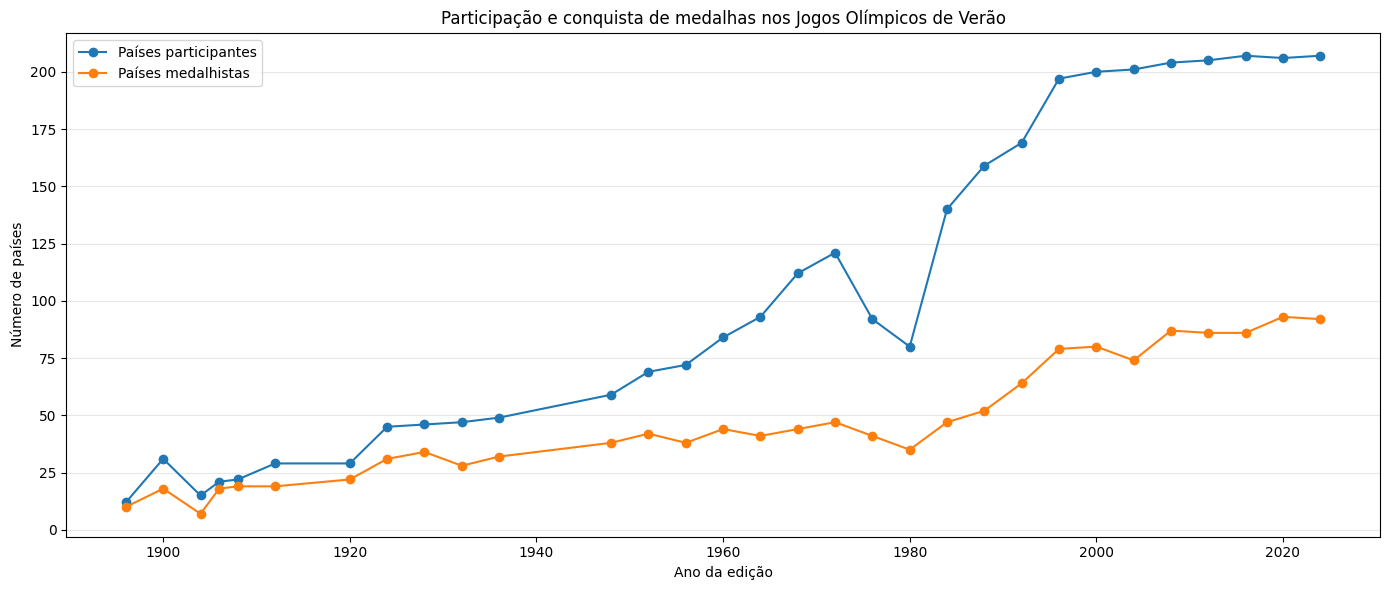

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    resumo_edicoes['year'],
    resumo_edicoes['participantes'],
    marker='o',
    label='Países participantes'
)

plt.plot(
    resumo_edicoes['year'],
    resumo_edicoes['medalhistas'],
    marker='o',
    label='Países medalhistas'
)

plt.title('Participação e conquista de medalhas nos Jogos Olímpicos de Verão')
plt.xlabel('Ano da edição')
plt.ylabel('Número de países')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


Para observar diretamente como o número de medalhas por país varia entre as edições, a análise é complementada com a evolução da média e da mediana:


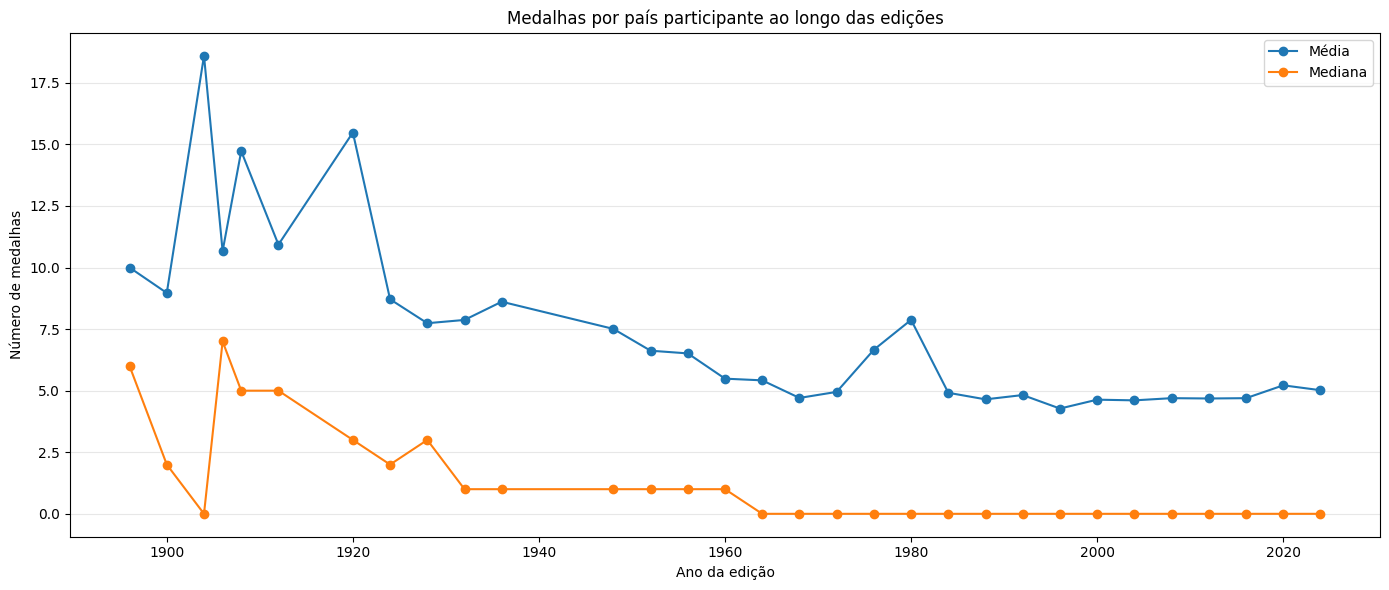

In [5]:
plt.figure(figsize=(14, 6))

plt.plot(
    resumo_edicoes['year'],
    resumo_edicoes['media_medalhas'],
    marker='o',
    label='Média'
)

plt.plot(
    resumo_edicoes['year'],
    resumo_edicoes['mediana_medalhas'],
    marker='o',
    label='Mediana'
)

plt.title('Medalhas por país participante ao longo das edições')
plt.xlabel('Ano da edição')
plt.ylabel('Número de medalhas')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Análise e Resposta**

Os dados mostram que o contexto competitivo dos Jogos Olímpicos mudou substancialmente ao longo do período analisado. Em 1896, a base registra **12 países participantes e 120 medalhas**, enquanto em 2024 aparecem **207 países participantes e 1.044 medalhas**. Portanto, tanto a quantidade de delegações quanto a quantidade de medalhas disponíveis aumentaram consideravelmente ao longo da história dos Jogos.

Entretanto, o aumento do número total de medalhas não significou um aumento equivalente no número de medalhas conquistadas pelo país participante típico. Em 1896, a média era de **10 medalhas por país** e a mediana era de **6**. Em 2024, apesar de haver muito mais medalhas disponíveis, a média foi de aproximadamente **5 medalhas por país**, enquanto a mediana foi **zero**.

A mediana igual a zero nas edições mais recentes significa que pelo menos metade dos países participantes terminou essas edições sem conquistar nenhuma medalha. Esse padrão aparece de forma persistente na base a partir de 1964. Ao mesmo tempo, existem países que conquistam dezenas ou até mais de uma centena de medalhas em uma única edição, fazendo com que a média seja consideravelmente superior à mediana.

Também houve crescimento no número absoluto de países medalhistas. Em 1896, **10 dos 12 participantes** conquistaram pelo menos uma medalha. Em 2024, **92 dos 207 participantes** conquistaram medalhas. Assim, embora hoje muito mais países alcancem o pódio em números absolutos, o crescimento do número de participantes foi ainda maior.

Portanto, **o desempenho olímpico dos países varia bastante entre as edições tanto em nível quanto em distribuição**. As primeiras edições possuíam poucos participantes e um número relativamente elevado de medalhas por país. Com a expansão dos Jogos, aumentaram simultaneamente o número de países e o total de medalhas, mas o número de medalhas do país típico diminuiu. Nas edições contemporâneas, muitos países terminam sem medalhas, enquanto alguns apresentam totais muito elevados.

Essa diferença entre média e mediana também indica que a distribuição de medalhas é bastante assimétrica. A questão seguinte permitirá investigar mais diretamente até que ponto essas medalhas se concentram em um grupo reduzido de países.


### 2. Como as medalhas estão distribuídas entre os países participantes? Elas se concentram em um grupo relativamente pequeno de países?

**Transformação dos Dados**

Para analisar a distribuição das medalhas entre os países participantes, foram consideradas todas as edições dos Jogos Olímpicos de Verão disponíveis na base, entre 1896 e 2024.

Como a base abrange mais de um século de Jogos Olímpicos, alguns códigos representam delegações ou entidades históricas, como União Soviética e Alemanha Oriental. Por isso, nesta análise, os países são identificados pelos códigos dos Comitês Olímpicos Nacionais (NOCs) registrados na base.

Primeiramente, foi calculado o total de medalhas conquistado por cada NOC ao longo de todo o período. Em seguida, os NOCs foram ordenados do maior para o menor número de medalhas e foram calculadas suas participações percentual e acumulada no total de medalhas.


In [6]:
# Remove apenas observações sem código NOC identificável
df_q2 = df_olimpico_completo[
    df_olimpico_completo['noc'].notna()
].copy()

# Total de medalhas de cada NOC em todas as edições
medalhas_por_noc = (
    df_q2
    .groupby('noc', as_index=False)
    .agg(total_medalhas=('total', 'sum'))
    .sort_values('total_medalhas', ascending=False)
    .reset_index(drop=True)
)

# Participação de cada NOC no total de medalhas
total_medalhas_historico = medalhas_por_noc['total_medalhas'].sum()

medalhas_por_noc['participacao_pct'] = (
    medalhas_por_noc['total_medalhas']
    / total_medalhas_historico
    * 100
)

medalhas_por_noc['participacao_acumulada_pct'] = (
    medalhas_por_noc['participacao_pct'].cumsum()
)

medalhas_por_noc['posicao'] = (
    medalhas_por_noc.index + 1
)

medalhas_por_noc.head(20)


,noc,total_medalhas,participacao_pct,participacao_acumulada_pct,posicao
0,USA,2806,15.430300,15.430300,1
1,GBR,1019,5.603519,21.033819,2
2,URS,1010,5.554028,26.587847,3
3,FRA,877,4.822656,31.410503,4
4,GER,845,4.646687,36.057190,5
5,CHN,727,3.997800,40.054990,6
6,ITA,688,3.783338,43.838328,7
7,AUS,597,3.282925,47.121254,8
8,HUN,544,2.991476,50.112730,9
9,JPN,544,2.991476,53.104207,10


A concentração histórica das medalhas pode ser visualizada pela participação acumulada dos NOCs, ordenados do maior para o menor número de medalhas:


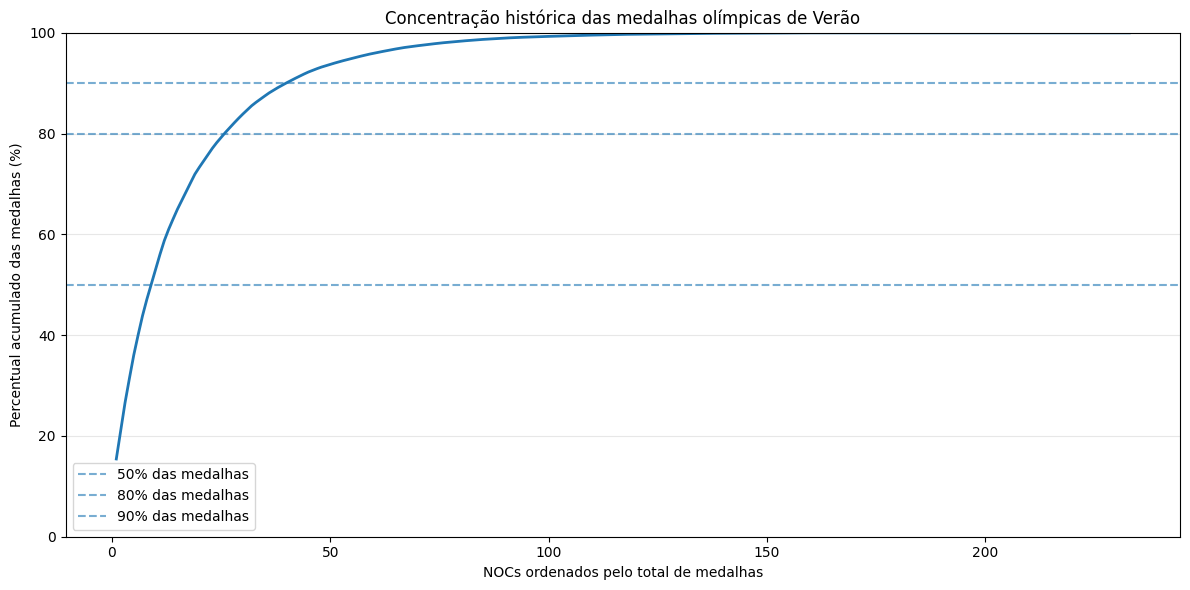

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    medalhas_por_noc['posicao'],
    medalhas_por_noc['participacao_acumulada_pct'],
    linewidth=2
)

plt.axhline(50, linestyle='--', alpha=0.6, label='50% das medalhas')
plt.axhline(80, linestyle='--', alpha=0.6, label='80% das medalhas')
plt.axhline(90, linestyle='--', alpha=0.6, label='90% das medalhas')

plt.title('Concentração histórica das medalhas olímpicas de Verão')
plt.xlabel('NOCs ordenados pelo total de medalhas')
plt.ylabel('Percentual acumulado das medalhas (%)')

plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Como o número de participantes aumentou muito ao longo da história dos Jogos, também é útil verificar se essa concentração ocorre dentro de cada edição. Para isso, foi calculada a parcela das medalhas conquistada pelos dez NOCs com maior número de medalhas em cada edição.


In [8]:
# Ordena os países dentro de cada edição
ranking_edicao = (
    df_q2
    .sort_values(
        ['year', 'total'],
        ascending=[True, False]
    )
    .copy()
)

# Posição do país dentro da edição
ranking_edicao['posicao_edicao'] = (
    ranking_edicao
    .groupby('year')
    .cumcount() + 1
)

# Total de medalhas distribuídas em cada edição
ranking_edicao['total_edicao'] = (
    ranking_edicao
    .groupby('year')['total']
    .transform('sum')
)

# Participação percentual de cada país
ranking_edicao['participacao_pct'] = (
    ranking_edicao['total']
    / ranking_edicao['total_edicao']
    * 100
)

# Participação conjunta dos 10 primeiros de cada edição
concentracao_top10 = (
    ranking_edicao[
        ranking_edicao['posicao_edicao'] <= 10
    ]
    .groupby('year', as_index=False)
    .agg(
        participacao_top10=('participacao_pct', 'sum')
    )
)

concentracao_top10


,year,participacao_top10
0,1896,100.000000
1,1900,92.446043
2,1904,100.000000
3,1906,87.053571
4,1908,91.358025
5,1912,86.750789
6,1920,89.309577
7,1924,80.867347
8,1928,75.000000
9,1932,82.702703


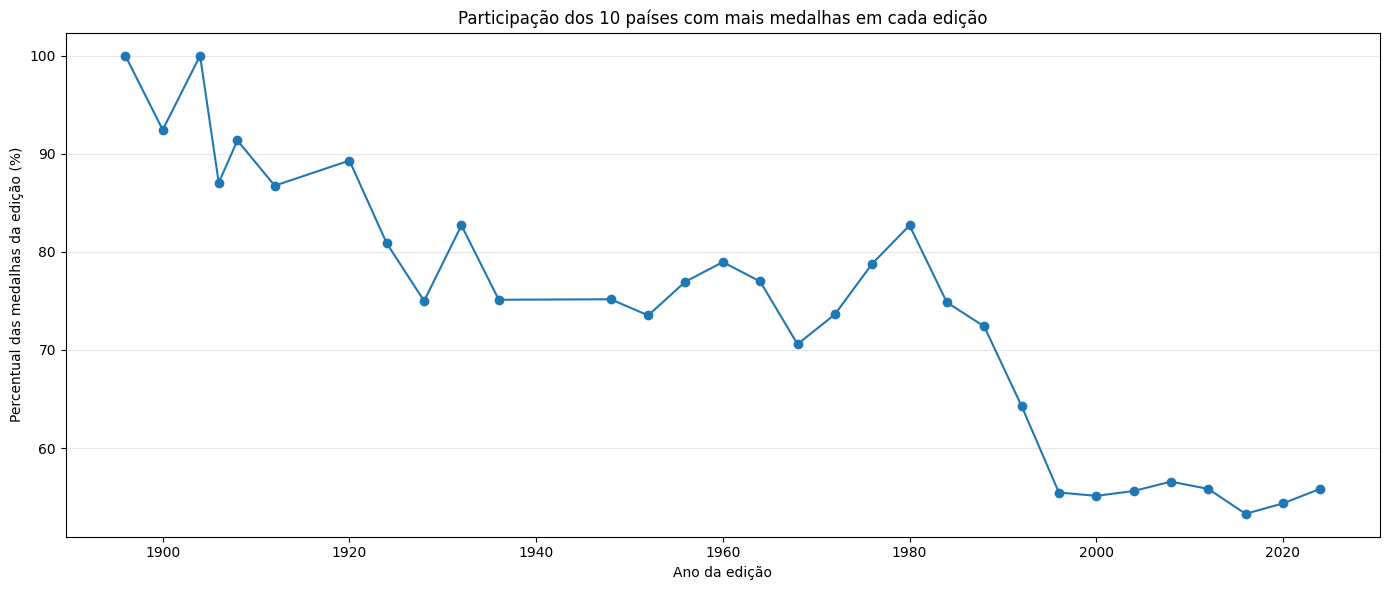

In [9]:
plt.figure(figsize=(14, 6))

plt.plot(
    concentracao_top10['year'],
    concentracao_top10['participacao_top10'],
    marker='o'
)

plt.title('Participação dos 10 países com mais medalhas em cada edição')
plt.xlabel('Ano da edição')
plt.ylabel('Percentual das medalhas da edição (%)')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Análise e Resposta**

A distribuição histórica das medalhas apresenta forte concentração. Ao longo das edições de Verão analisadas, aparecem **233 NOCs diferentes**, dos quais **156 conquistaram pelo menos uma medalha** e **77 nunca conquistaram medalhas** no período registrado na base.

No total, foram contabilizadas **18.185 medalhas**. Entretanto, essas medalhas estão distribuídas de maneira bastante desigual. Apenas os **9 NOCs com mais medalhas acumuladas concentram pouco mais de 50% de todas as medalhas** do período. Considerando os dez primeiros, essa participação chega a aproximadamente **53,1%**.

A concentração continua evidente quando ampliamos o grupo: os **20 NOCs com mais medalhas acumulam aproximadamente 73,3%** de todas as medalhas, enquanto apenas **40 NOCs concentram cerca de 90,1%** do total histórico. Portanto, uma parcela relativamente pequena das delegações é responsável pela maior parte das medalhas distribuídas ao longo dos Jogos.

Esse resultado histórico, entretanto, deve ser interpretado com cuidado. Países que participaram de muitas edições tiveram mais oportunidades de acumular medalhas, e a base contém também delegações históricas que não existem mais na mesma forma, como a União Soviética e a Alemanha Oriental. Por isso, o total acumulado não deve ser interpretado simplesmente como um ranking atual de desempenho.

A análise por edição confirma, porém, que a concentração não é apenas consequência do acúmulo histórico. Nas edições mais recentes, os dez países com maior número de medalhas continuam concentrando mais da metade das medalhas disponíveis. Em 2000, os dez primeiros receberam aproximadamente **55,1%** das medalhas; em 2008, **56,6%**; em 2016, **53,3%**; e em 2024, **55,8%**.

Em 2024, por exemplo, havia **207 NOCs participantes**, mas apenas **92 conquistaram ao menos uma medalha**, enquanto **115 terminaram a edição sem medalhas**. Além disso, os vinte países com maior desempenho concentraram aproximadamente **71,5%** de todas as medalhas daquela edição.

Assim, os dados indicam que **as medalhas olímpicas estão fortemente concentradas em um grupo relativamente pequeno de países**. Essa concentração era ainda mais extrema nas primeiras edições, quando o número de participantes era menor, e diminuiu com a expansão dos Jogos. Mesmo assim, permanece elevada nas edições contemporâneas: mais de metade das medalhas continua sendo conquistada pelos dez países de maior desempenho de cada edição.


### 3. Países com populações maiores tendem a conquistar mais medalhas?

**Transformação dos Dados**

Como esta pergunta envolve um indicador socioeconômico, foram consideradas apenas as edições dos Jogos Olímpicos de Verão entre **1960 e 2024**, período de sobreposição com os dados de população do World Bank.

A unidade de análise continua sendo **país × edição olímpica**. Países que participaram de uma edição e não conquistaram medalhas permanecem na base com `total = 0`. Para esta pergunta, são excluídas apenas as observações que não possuem informação de população.

A população apresenta valores muito diferentes entre os países, variando por várias ordens de grandeza. Por isso, o gráfico de dispersão utiliza escala logarítmica no eixo da população. Além da inspeção visual, é calculada a correlação de Spearman, que mede a associação monotônica entre duas variáveis por meio de suas posições no ranking e é menos sensível que a correlação de Pearson à forte assimetria da população e a valores extremos.

Como a população mundial também cresceu ao longo do período, a análise é complementada agrupando os países em **quartis de população dentro de cada edição**. Dessa forma, a comparação é feita entre países relativamente menores e maiores no contexto de cada Olimpíada, evitando comparar diretamente o tamanho populacional absoluto de 1960 com o de 2024.


In [10]:
# Seleciona apenas observações com população disponível
df_q3 = (
    df_socioeconomico
    .dropna(subset=['population'])
    .copy()
)

observacoes_totais_q3 = len(df_socioeconomico)
observacoes_validas_q3 = len(df_q3)
ausentes_populacao = df_socioeconomico['population'].isna().sum()

print(f'Observações no recorte 1960–2024: {observacoes_totais_q3}')
print(f'Observações com população disponível: {observacoes_validas_q3}')
print(f'Observações sem população: {ausentes_populacao}')

# Correlação de Spearman entre população e total de medalhas
correlacao_spearman_pop = (
    df_q3[['population', 'total']]
    .corr(method='spearman')
    .loc['population', 'total']
)

print(f'Correlação de Spearman: {correlacao_spearman_pop:.3f}')


Observações no recorte 1960–2024: 2679
Observações com população disponível: 2584
Observações sem população: 95
Correlação de Spearman: 0.477


O gráfico de dispersão abaixo mostra a relação entre população e número de medalhas para cada observação país × edição. A escala logarítmica no eixo horizontal é utilizada porque existem diferenças de várias ordens de grandeza entre as populações dos países.


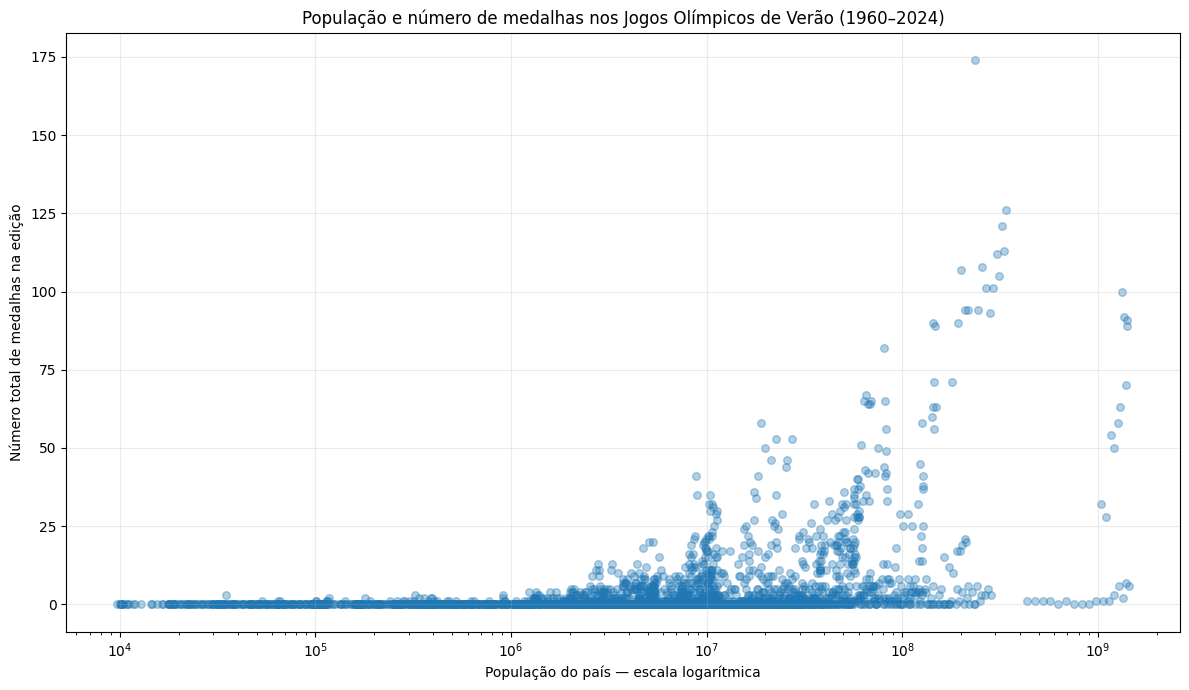

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.scatter(
    df_q3['population'],
    df_q3['total'],
    alpha=0.35,
    s=30
)

plt.xscale('log')

plt.title('População e número de medalhas nos Jogos Olímpicos de Verão (1960–2024)')
plt.xlabel('População do país — escala logarítmica')
plt.ylabel('Número total de medalhas na edição')

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


Para complementar o gráfico de dispersão, os países foram divididos em quatro grupos de tamanho populacional **dentro de cada edição**. O primeiro quartil reúne os países relativamente menos populosos daquela edição, enquanto o quarto quartil reúne os relativamente mais populosos.


In [12]:
# Cria quartis de população separadamente em cada edição
# O rank(method='first') evita problemas de corte quando existem valores empatados.
rotulos_quartis = [
    'Q1 - menor população',
    'Q2',
    'Q3',
    'Q4 - maior população'
]

df_q3['quartil_populacao'] = (
    df_q3
    .groupby('year')['population']
    .transform(
        lambda x: pd.qcut(
            x.rank(method='first'),
            q=4,
            labels=rotulos_quartis
        )
    )
)

# Resume o desempenho em cada quartil
resumo_quartis_pop = (
    df_q3
    .groupby('quartil_populacao', observed=False)
    .agg(
        observacoes=('total', 'size'),
        media_medalhas=('total', 'mean'),
        mediana_medalhas=('total', 'median'),
        proporcao_medalhistas=(
            'total',
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
)

resumo_quartis_pop


,quartil_populacao,observacoes,media_medalhas,mediana_medalhas,proporcao_medalhistas
0,Q1 - menor população,653,0.140888,0.0,9.341501
1,Q2,645,1.537984,0.0,37.364341
2,Q3,638,3.860502,0.0,44.670846
3,Q4 - maior população,648,12.279321,3.0,69.290123


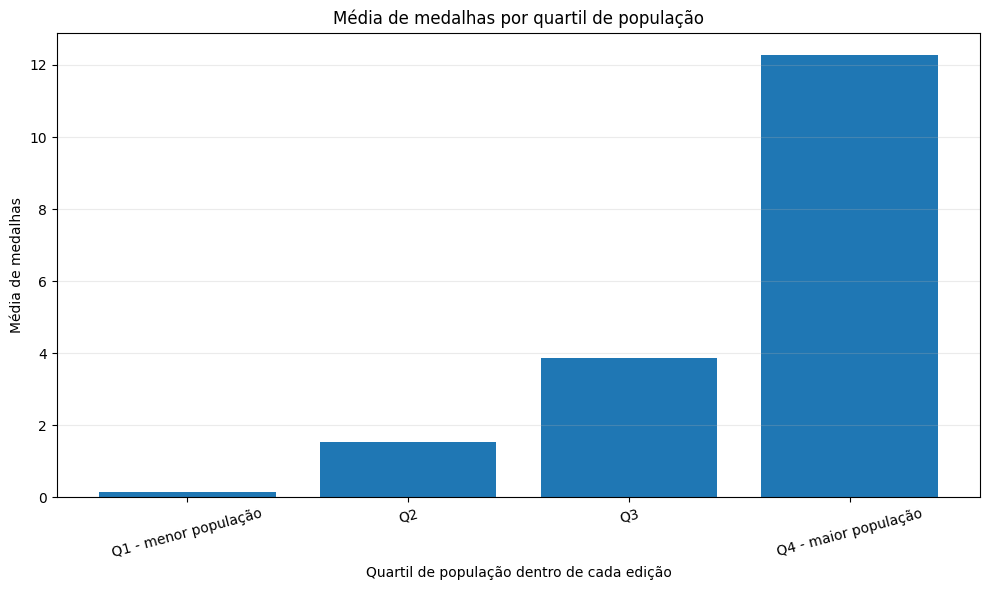

In [13]:
plt.figure(figsize=(10, 6))

plt.bar(
    resumo_quartis_pop['quartil_populacao'].astype(str),
    resumo_quartis_pop['media_medalhas']
)

plt.title('Média de medalhas por quartil de população')
plt.xlabel('Quartil de população dentro de cada edição')
plt.ylabel('Média de medalhas')

plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


**Análise e Resposta**

No recorte de 1960 a 2024, a base contém **2.679 observações país × edição**, das quais **2.584 possuem informação de população** e podem ser utilizadas nesta análise. As 95 observações restantes foram mantidas como ausentes na base geral e são excluídas apenas desta pergunta. Entre elas estão algumas delegações históricas, como União Soviética e Alemanha Oriental, para as quais não existe uma correspondência direta e defensável com os países atuais do World Bank. Essa ausência deve ser considerada uma limitação da análise.

O gráfico de dispersão sugere uma **associação positiva entre população e número de medalhas**: observações correspondentes a países mais populosos aparecem com maior frequência entre os maiores totais de medalhas. Entretanto, existe grande dispersão. Há países muito populosos que conquistam poucas ou nenhuma medalha e, ao mesmo tempo, países de população bem menor que apresentam resultados relativamente elevados.

A correlação de Spearman entre população e total de medalhas é de aproximadamente **0,48**. O valor positivo confirma a tendência observada no gráfico: à medida que a população aumenta, o número de medalhas tende também a ocupar posições mais altas. No entanto, a relação está longe de ser perfeita, mostrando que o tamanho da população, isoladamente, não determina o desempenho olímpico.

A comparação por quartis reforça esse padrão. Dentro de cada edição, os países pertencentes ao **quartil de menor população (Q1)** conquistaram, em média, aproximadamente **0,14 medalha por participação**, e apenas cerca de **9,3%** dessas observações correspondem a países que conquistaram pelo menos uma medalha. No segundo quartil, a média sobe para aproximadamente **1,54 medalha**, e no terceiro, para **3,86 medalhas**.

No **quartil de maior população (Q4)**, a média alcança aproximadamente **12,28 medalhas por participação**, e cerca de **69,3%** das observações correspondem a países medalhistas. A mediana desse grupo é de **3 medalhas**, enquanto a mediana dos três primeiros quartis é zero.

Portanto, **os dados indicam que países com populações maiores tendem a conquistar mais medalhas olímpicas**. A associação aparece tanto no gráfico de dispersão quanto na comparação entre grupos de população. Contudo, a ampla variabilidade dentro de cada faixa populacional mostra que população não é suficiente para explicar o desempenho: países de tamanhos semelhantes podem apresentar resultados olímpicos muito diferentes.

Além disso, essa análise identifica apenas uma associação. Não é possível concluir que uma população maior cause diretamente um melhor desempenho olímpico. Outros fatores, inclusive econômicos, podem estar relacionados ao resultado, o que será explorado nas perguntas seguintes.


### 4. Existe associação entre o PIB de um país e seu número de medalhas conquistadas?

**Transformação dos Dados**

Como esta pergunta utiliza o PIB, foram consideradas apenas as edições dos Jogos Olímpicos de Verão entre **1960 e 2024**, período de sobreposição com os dados do World Bank.

A unidade de análise permanece sendo **país × edição olímpica**, e países participantes que não conquistaram medalhas continuam representados com `total = 0`. Para esta pergunta, são excluídas somente as observações sem informação de PIB.

O indicador utilizado é o PIB em **dólares correntes** (`NY.GDP.MKTP.CD`). Como valores monetários correntes de anos muito distantes não são diretamente comparáveis devido, entre outros fatores, à inflação e a variações cambiais, a análise não se baseará apenas nos valores absolutos combinados ao longo de todo o período.

O gráfico de dispersão utiliza escala logarítmica no eixo do PIB para representar adequadamente países cujas economias diferem por várias ordens de grandeza. Para a medida de associação principal, cada país recebe também sua **posição percentual de PIB dentro da própria edição olímpica**. Assim, comparamos se países relativamente maiores economicamente em cada edição tendem a conquistar mais medalhas, sem depender da comparação direta entre dólares de 1960 e dólares de 2024.


In [14]:
# Seleciona somente observações com PIB disponível
df_q4 = (
    df_socioeconomico
    .dropna(subset=['gdp'])
    .copy()
)

observacoes_totais_q4 = len(df_socioeconomico)
observacoes_validas_q4 = len(df_q4)
ausentes_gdp = df_socioeconomico['gdp'].isna().sum()

print(f'Observações no recorte 1960–2024: {observacoes_totais_q4}')
print(f'Observações com PIB disponível: {observacoes_validas_q4}')
print(f'Observações sem PIB: {ausentes_gdp}')

# Posição percentual do PIB dentro de cada edição.
# Valores próximos de 1 representam os maiores PIBs daquela edição.
df_q4['percentil_gdp_edicao'] = (
    df_q4
    .groupby('year')['gdp']
    .rank(method='average', pct=True)
)

# Correlação de Spearman entre posição relativa do PIB e medalhas
correlacao_spearman_gdp = (
    df_q4[['percentil_gdp_edicao', 'total']]
    .corr(method='spearman')
    .loc['percentil_gdp_edicao', 'total']
)

print(
    'Correlação de Spearman entre posição relativa do PIB '
    f'e medalhas: {correlacao_spearman_gdp:.3f}'
)


Observações no recorte 1960–2024: 2679
Observações com PIB disponível: 2447
Observações sem PIB: 232
Correlação de Spearman entre posição relativa do PIB e medalhas: 0.667


O gráfico abaixo mostra a relação entre o PIB e o número de medalhas nas observações país × edição. A escala logarítmica no eixo horizontal é necessária porque os PIBs apresentam diferenças de várias ordens de grandeza. Como o PIB está expresso em dólares correntes, o gráfico deve ser interpretado principalmente como uma visualização exploratória da associação, e não como uma comparação direta de níveis monetários entre décadas.


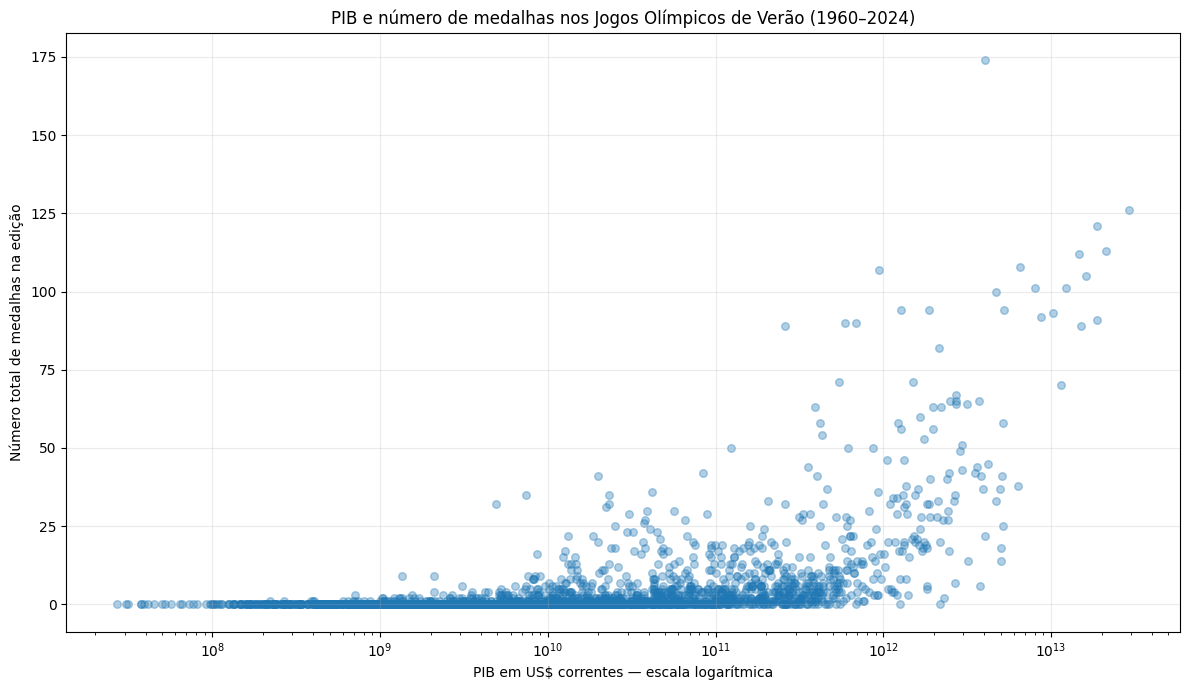

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.scatter(
    df_q4['gdp'],
    df_q4['total'],
    alpha=0.35,
    s=30
)

plt.xscale('log')

plt.title('PIB e número de medalhas nos Jogos Olímpicos de Verão (1960–2024)')
plt.xlabel('PIB em US$ correntes — escala logarítmica')
plt.ylabel('Número total de medalhas na edição')

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


Para tornar a comparação entre diferentes edições mais adequada, os países foram divididos em **quartis de PIB dentro de cada edição**. O primeiro quartil reúne os países com os menores PIBs relativos daquela edição e o quarto quartil reúne os maiores. Em seguida, são comparados o número médio e mediano de medalhas e a proporção de países que conquistaram pelo menos uma medalha.


In [16]:
# Quartis de PIB calculados separadamente em cada edição
rotulos_quartis_gdp = [
    'Q1 - menor PIB',
    'Q2',
    'Q3',
    'Q4 - maior PIB'
]

df_q4['quartil_gdp'] = (
    df_q4
    .groupby('year')['gdp']
    .transform(
        lambda x: pd.qcut(
            x.rank(method='first'),
            q=4,
            labels=rotulos_quartis_gdp
        )
    )
)

resumo_quartis_gdp = (
    df_q4
    .groupby('quartil_gdp', observed=False)
    .agg(
        observacoes=('total', 'size'),
        media_medalhas=('total', 'mean'),
        mediana_medalhas=('total', 'median'),
        proporcao_medalhistas=(
            'total',
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
)

resumo_quartis_gdp


,quartil_gdp,observacoes,media_medalhas,mediana_medalhas,proporcao_medalhistas
0,Q1 - menor PIB,618,0.108414,0.0,7.281553
1,Q2,612,0.584967,0.0,21.241830
2,Q3,604,3.100993,0.0,47.350993
3,Q4 - maior PIB,613,14.176183,5.0,86.949429


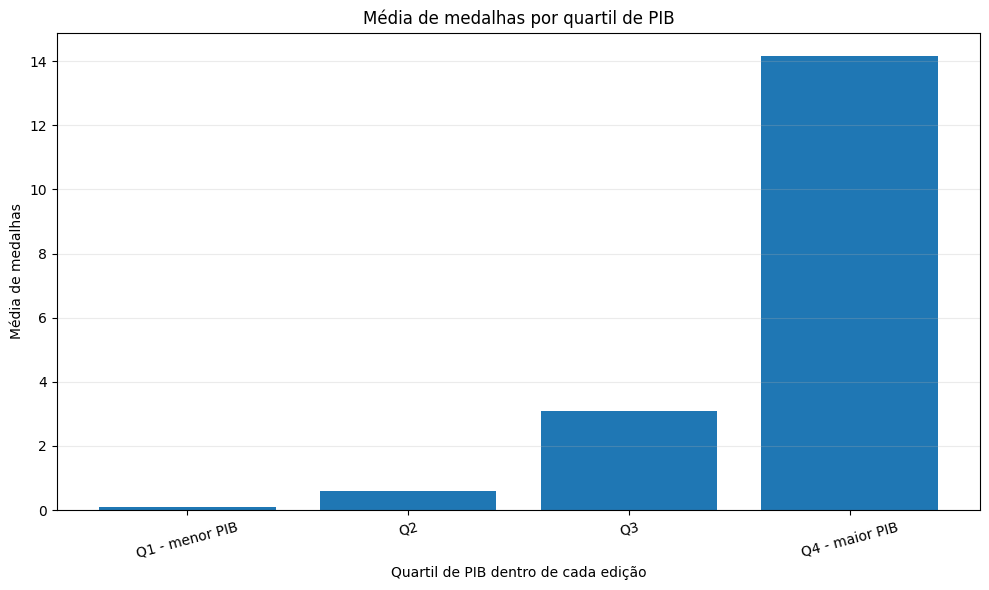

In [17]:
plt.figure(figsize=(10, 6))

plt.bar(
    resumo_quartis_gdp['quartil_gdp'].astype(str),
    resumo_quartis_gdp['media_medalhas']
)

plt.title('Média de medalhas por quartil de PIB')
plt.xlabel('Quartil de PIB dentro de cada edição')
plt.ylabel('Média de medalhas')

plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


**Análise e Resposta**

No período de 1960 a 2024, a base possui **2.679 observações país × edição**. Destas, **2.447 possuem informação de PIB** e são utilizadas nesta pergunta; **232 observações não possuem o indicador** e são excluídas apenas desta análise.

O gráfico de dispersão apresenta um padrão de associação positiva: os maiores totais de medalhas aparecem com maior frequência entre países de PIB elevado. Ao mesmo tempo, a dispersão é considerável, pois países com níveis econômicos semelhantes podem apresentar números de medalhas bastante diferentes.

Para evitar que a comparação entre valores de PIB em dólares correntes de décadas diferentes distorça a interpretação, foi calculada a posição relativa do PIB de cada país dentro de sua própria edição olímpica. A correlação de Spearman entre essa posição relativa e o total de medalhas é de aproximadamente **0,67**, indicando uma associação positiva relativamente clara: países que ocupam posições mais altas na distribuição de PIB de uma edição tendem também a ocupar posições mais altas em número de medalhas.

A comparação por quartis reforça esse resultado. Entre os países do **quartil de menor PIB (Q1)**, a média é de aproximadamente **0,11 medalha por participação**, e apenas cerca de **7,3%** das observações correspondem a países que conquistaram pelo menos uma medalha. No segundo quartil, a média sobe para cerca de **0,58 medalha**, e no terceiro quartil chega a aproximadamente **3,10 medalhas**.

No **quartil de maior PIB (Q4)**, a média alcança aproximadamente **14,18 medalhas por participação**. Além disso, cerca de **86,9%** das observações desse grupo correspondem a países medalhistas, e a mediana é de **5 medalhas**. Nos três primeiros quartis, a mediana é zero.

Portanto, **os dados mostram uma associação positiva entre PIB total e desempenho olímpico medido pelo número de medalhas**. Países com economias relativamente maiores dentro de cada edição tendem a conquistar mais medalhas e apresentam uma probabilidade muito maior de conquistar ao menos uma.

Essa associação, entretanto, não implica causalidade. O PIB total também está relacionado ao tamanho da população e não informa como a riqueza está distribuída entre os habitantes nem quanto um país efetivamente investe em esporte. Assim, não é possível concluir que um PIB maior, por si só, cause um melhor desempenho olímpico. A próxima pergunta, ao utilizar o PIB per capita, permite investigar se a relação se mantém quando o tamanho da economia é considerado de uma forma diferente.


### 5. A relação observada muda quando utilizamos PIB per capita em vez de PIB total?

**Transformação dos Dados:**

*(Documente aqui as agregações, derivações e limpezas feitas especificamente para responder a esta pergunta. Por exemplo, agrupar medalhas por equipe, ou derivar medalhas/milhão de habitantes)*

In [18]:
# Código para transformação de dados e geração do gráfico para a 5ª Pergunta
# ...
# plt.show()

**Análise e Resposta:**

*(Interprete o gráfico gerado acima e responda diretamente à pergunta, lembrando de discutir em termos de associação e não causalidade.)*

### 6. Como a comparação entre os países muda quando utilizamos medidas relativas, como medalhas por milhão de habitantes, em vez do número absoluto de medalhas?

**Transformação dos Dados:**

*(Documente aqui as agregações, derivações e limpezas feitas especificamente para responder a esta pergunta. Por exemplo, agrupar medalhas por equipe, ou derivar medalhas/milhão de habitantes)*

In [19]:
# Código para transformação de dados e geração do gráfico para a 6ª Pergunta
# ...
# plt.show()

**Análise e Resposta:**

*(Interprete o gráfico gerado acima e responda diretamente à pergunta, lembrando de discutir em termos de associação e não causalidade.)*

### 7. Quais países apresentam desempenho olímpico muito acima ou abaixo do padrão observado para países com características socioeconômicas semelhantes?

**Transformação dos Dados:**

*(Documente aqui as agregações, derivações e limpezas feitas especificamente para responder a esta pergunta. Por exemplo, agrupar medalhas por equipe, ou derivar medalhas/milhão de habitantes)*

In [20]:
# Código para transformação de dados e geração do gráfico para a 7ª Pergunta
# ...
# plt.show()

**Análise e Resposta:**

*(Interprete o gráfico gerado acima e responda diretamente à pergunta, lembrando de discutir em termos de associação e não causalidade.)*

### 8. Essas relações entre características socioeconômicas e desempenho olímpico permanecem semelhantes ao longo das diferentes edições dos Jogos?

**Transformação dos Dados:**

*(Documente aqui as agregações, derivações e limpezas feitas especificamente para responder a esta pergunta. Por exemplo, agrupar medalhas por equipe, ou derivar medalhas/milhão de habitantes)*

In [21]:
# Código para transformação de dados e geração do gráfico para a 8ª Pergunta
# ...
# plt.show()

**Análise e Resposta:**

*(Interprete o gráfico gerado acima e responda diretamente à pergunta, lembrando de discutir em termos de associação e não causalidade.)*

## Conclusão

*(Escreva a síntese final do trabalho, as recomendações e as limitações encontradas na análise, como por exemplo, problemas de padronização ao unir a base esportiva à do Banco Mundial.)*